# Name: Sayem Ahmed
## Id  : 011201379

In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

In [140]:
df=pd.read_csv('Merge_data_mean_v5.csv')

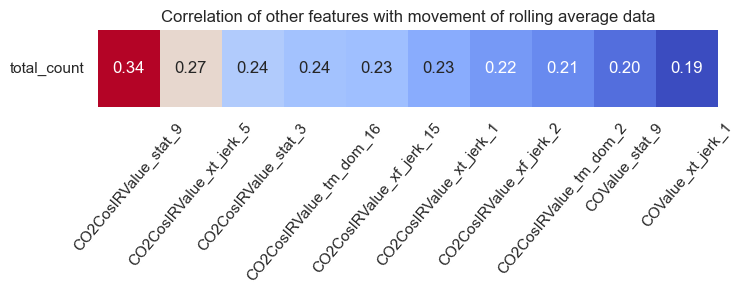

In [143]:
import seaborn as sns
import matplotlib.pyplot as plt

# Extract only the last row (which corresponds to 'total_count')
total_count_corr = top_correlation_matrix.iloc[-1:]

# Create a heatmap for the last row
plt.figure(figsize=(8, 1))  # Adjust the figure size as needed
heatmap = sns.heatmap(total_count_corr, annot=True, cmap='coolwarm', fmt=".2f", cbar=False)

plt.title("Correlation of other features with movement of rolling average data")
plt.xticks(rotation=50)  # Rotate x-axis labels if needed
plt.yticks(rotation=0)   # Rotate y-axis labels if needed
plt.show()

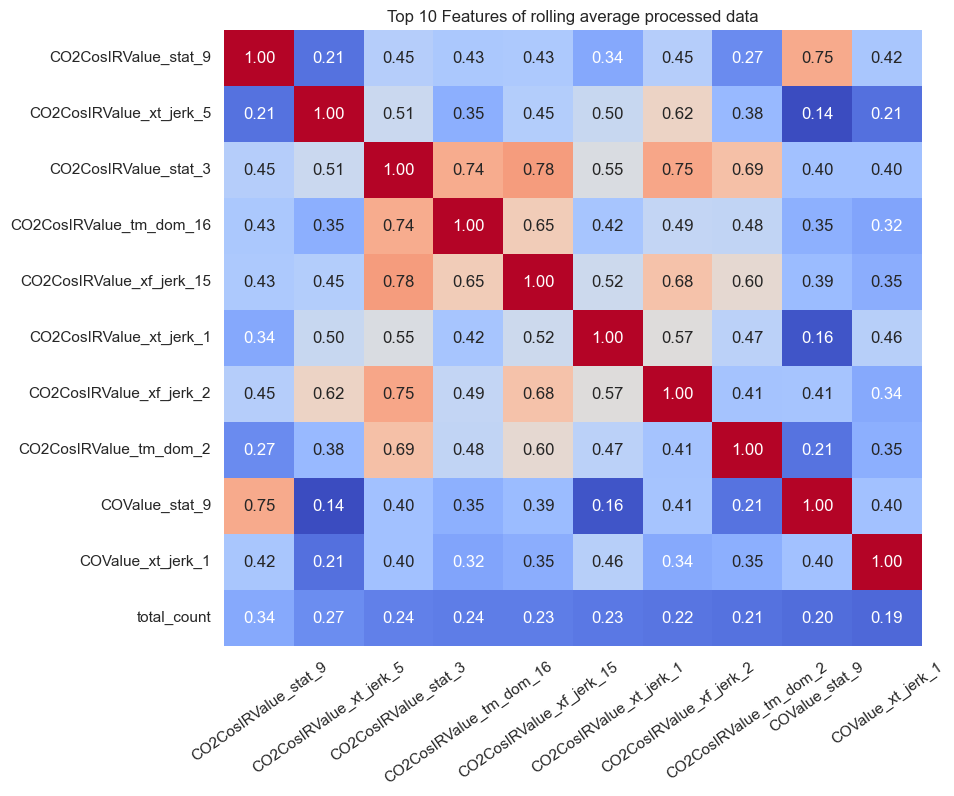

In [136]:
correlation_matrix = df.corr()
top_correlated_features = correlation_matrix['total_count'].sort_values(ascending=False)[1:11]

# Get the top correlated features names
top_correlated_features_names = top_correlated_features.index.tolist()

# Include 'total_count' in the list of top correlated features
top_correlated_features_names.append('total_count')

# Extract the correlation values for these features
top_correlation_matrix = df[top_correlated_features_names].corr()

# Drop duplicate 'total_count' column if it exists
if 'total_count' in top_correlation_matrix.columns:
    top_correlation_matrix.drop(columns=['total_count'], inplace=True)
# Create a heatmap
plt.figure(figsize=(9, 8))
heatmap=sns.heatmap(top_correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar=False)
heatmap.set_xticklabels(heatmap.get_xticklabels(), rotation=35)

plt.title("Top 10 Features of rolling average processed data")
plt.show()

In [33]:
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_12452/2892012645.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df['total_count'], shade=True)


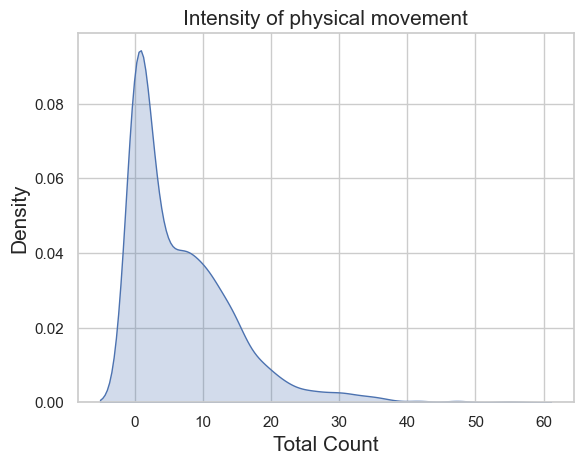

In [106]:
sns.kdeplot(data=df['total_count'], shade=True)
plt.title('Intensity of physical movement',fontsize=15)
plt.xlabel('Total Count',fontsize=15)
plt.ylabel('Density',fontsize=15)
plt.show()

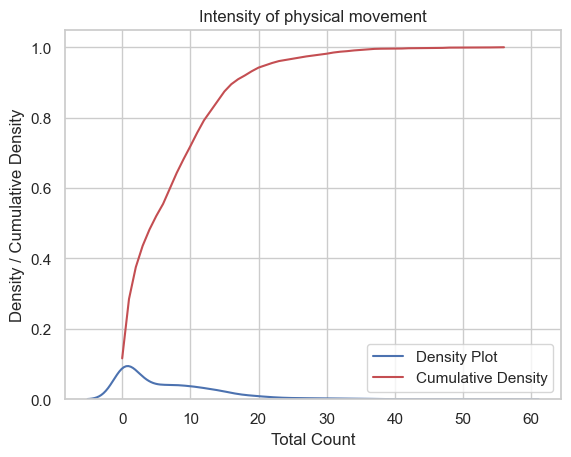

In [102]:
sns.kdeplot(data=df['total_count'], label='Density Plot')

# Plot cumulative density line
sorted_counts = df['total_count'].sort_values()
cumulative_density = sorted_counts.rank(method='average', pct=True)
plt.plot(sorted_counts, cumulative_density, color='r', label='Cumulative Density')

# Add legend
plt.legend()

# Add labels and title
plt.xlabel('Total Count')
plt.ylabel('Density / Cumulative Density')
plt.title('Intensity of physical movement')

# Show plot
plt.show()

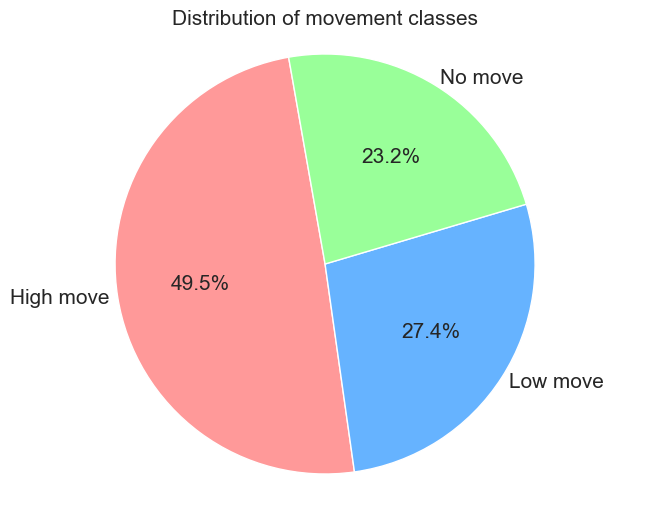

In [130]:
import matplotlib.pyplot as plt

move_type_counts = df['move_type'].value_counts()

# Define custom colors
colors = ['#ff9999','#66b3ff','#99ff99']

# Pie chart
plt.figure(figsize=(8, 6))
pie=plt.pie(move_type_counts, labels=['High move','Low move','No move'], autopct='%1.1f%%', startangle=100, labeldistance=1.04, textprops={'fontsize': 15}, colors=colors)
plt.title('Distribution of movement classes', fontsize=15)
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [134]:
del df['Unnamed: 0']

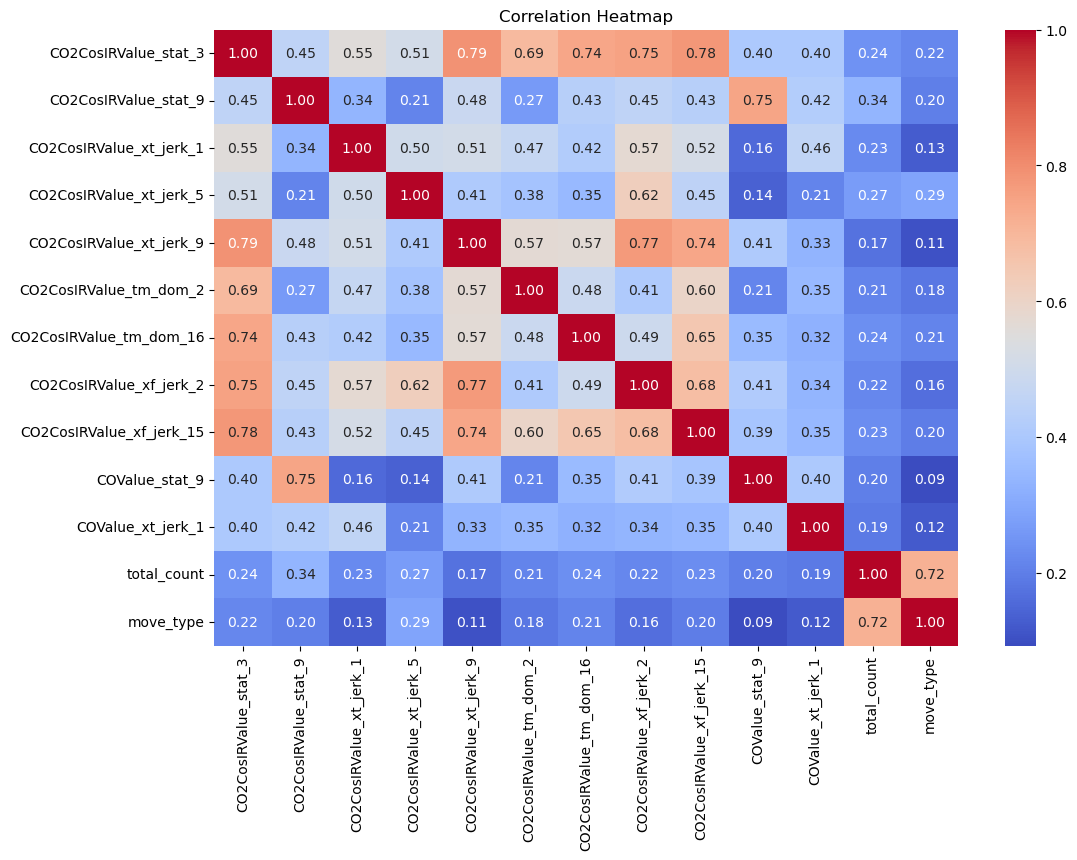

In [35]:
import seaborn as sns
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [36]:
drop_features = ['total_count','move_type']
target_feature = 'move_type'

In [37]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [38]:
X

,CO2CosIRValue_stat_3,CO2CosIRValue_stat_9,CO2CosIRValue_xt_jerk_1,CO2CosIRValue_xt_jerk_5,CO2CosIRValue_xt_jerk_9,CO2CosIRValue_tm_dom_2,CO2CosIRValue_tm_dom_16,CO2CosIRValue_xf_jerk_2,CO2CosIRValue_xf_jerk_15,COValue_stat_9,COValue_xt_jerk_1
0,4.277250,1.297384e+06,0.942857,1.039894,9.709796,0.462801,55.628117,0.054267,1.048591,1.641997e+06,0.285714
1,4.661196,1.215978e+06,2.064286,9.193603,16.844923,0.207858,83.595212,0.523647,9.918481,2.234549e+06,0.857143
2,2.928801,1.328604e+06,0.571429,5.519146,16.599365,1.668825,109.318905,0.573488,10.099731,2.098801e+06,0.411111
3,0.839037,1.363174e+06,1.165204,6.035382,6.908720,0.186527,47.409887,0.155241,4.268468,2.108054e+06,0.428571
4,1.316341,2.001046e+06,0.571429,5.530090,10.319739,0.729999,86.283489,0.267901,11.038523,2.591721e+06,0.285714
...,...,...,...,...,...,...,...,...,...,...,...
1932,0.779258,3.367352e+05,1.911111,8.488250,14.103951,0.095617,40.077413,0.192167,2.802264,3.954769e+06,0.333333
1933,0.985778,3.310420e+05,0.666667,0.807783,14.441360,0.383580,61.915949,0.110469,7.428919,4.022870e+06,4.488889
1934,1.150586,3.327721e+05,1.000000,2.368824,18.244583,0.341689,79.406058,0.323018,1.397248,3.983293e+06,0.666667
1935,0.818716,3.431804e+05,0.666667,0.152468,14.272867,0.039042,51.512676,0.157784,1.026341,4.064812e+06,0.666667


In [39]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=903)

In [40]:
from sklearn.metrics import classification_report

# Logistic classifier

In [41]:
model1 = LogisticRegression(max_iter=1000,multi_class='ovr', random_state=903,C=10,penalty='l2',solver='newton-cg')
model1.fit(X_train,y_train)
y_pred=model1.predict(X_test)

/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:457: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:306: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:416: LineSearchWarning: Rounding errors prevent the line search from converging
  warn(msg, LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/utils/optimize.py:203: UserWarning: Line Search failed
  warnings.warn("Line Search failed")


In [42]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.66
Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.85      0.78       117
           1       0.00      0.00      0.00       119
           2       0.64      0.89      0.75       249

    accuracy                           0.66       485
   macro avg       0.45      0.58      0.51       485
weighted avg       0.50      0.66      0.57       485



/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


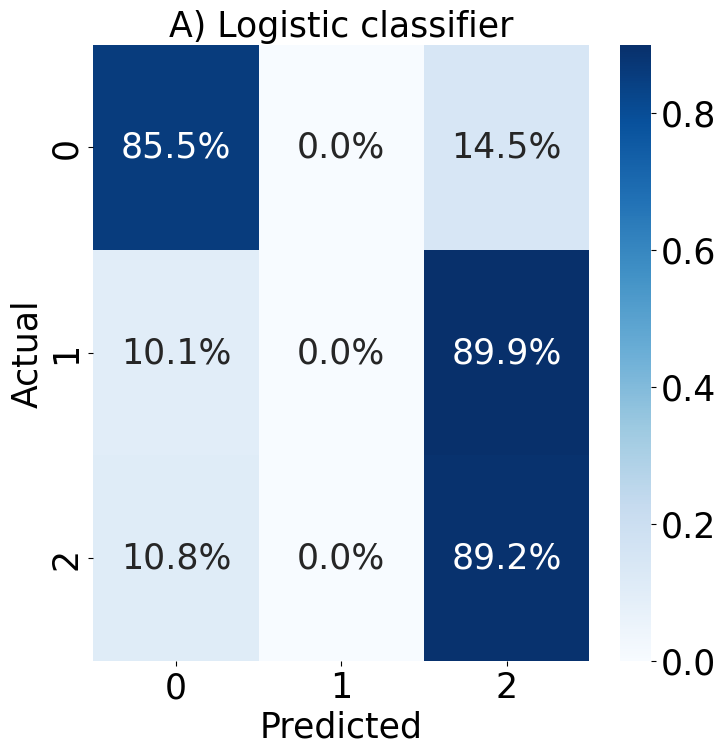

In [43]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('A) Logistic classifier',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
#cbar.set_ticks(np.linspace(0, .81, num=9))  # Set custom tick locations
#cbar.set_ticklabels(['0.0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8']) 
plt.show()

# Decision Tree

In [44]:
model2 = DecisionTreeClassifier(max_depth=3,criterion='entropy',min_samples_split=2,min_samples_leaf=1,splitter='best')
model2.fit(X_train,y_train)
y_pred=model2.predict(X_test)

In [45]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.70
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.74      0.84       117
           1       0.52      0.49      0.50       119
           2       0.69      0.78      0.73       249

    accuracy                           0.70       485
   macro avg       0.72      0.67      0.69       485
weighted avg       0.71      0.70      0.70       485



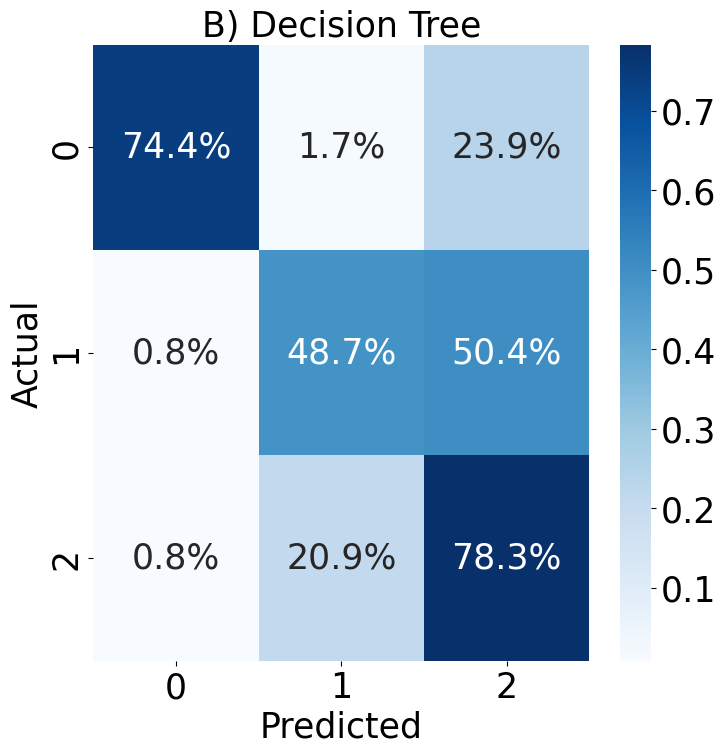

In [46]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('B) Decision Tree',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# Random Forest

In [68]:
model3 = RandomForestClassifier(n_estimators=350,max_depth=5)
model3.fit(X_train, y_train)

# Make predictions
y_pred = model3.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
report = classification_report(y_test, y_pred)
print("Classification Report:\n", report)

Accuracy: 0.7505154639175258
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.82      0.90       117
           1       0.66      0.33      0.44       119
           2       0.70      0.92      0.79       249

    accuracy                           0.75       485
   macro avg       0.78      0.69      0.71       485
weighted avg       0.76      0.75      0.73       485



In [69]:
y_pred_train = model3.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f'Accuracy: {accuracy}')

Accuracy: 0.7307162534435262


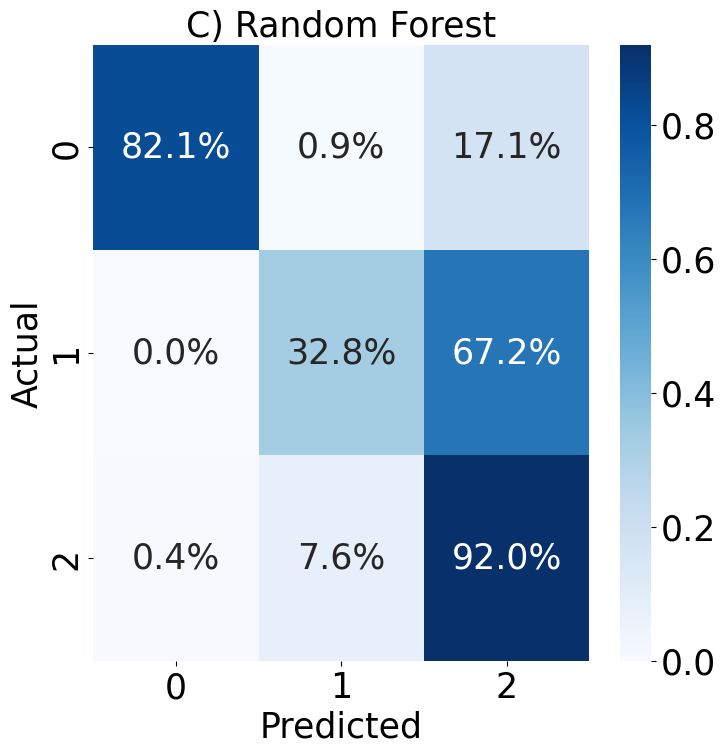

In [70]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('C) Random Forest',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# XGboost

In [71]:
model4=xgb.XGBClassifier(objective='multi:softmax',colsample_bytree=0.8,learning_rate=0.0001,max_depth=5,n_estimators=150,subsample=0.7, num_class=len(set(y)))
model4.fit(X_train,y_train)
y_pred=model4.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print("Classification Report:\n", report)

Accuracy: 0.755
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.83      0.90       117
           1       0.65      0.37      0.47       119
           2       0.71      0.90      0.79       249

    accuracy                           0.75       485
   macro avg       0.78      0.70      0.72       485
weighted avg       0.76      0.75      0.74       485



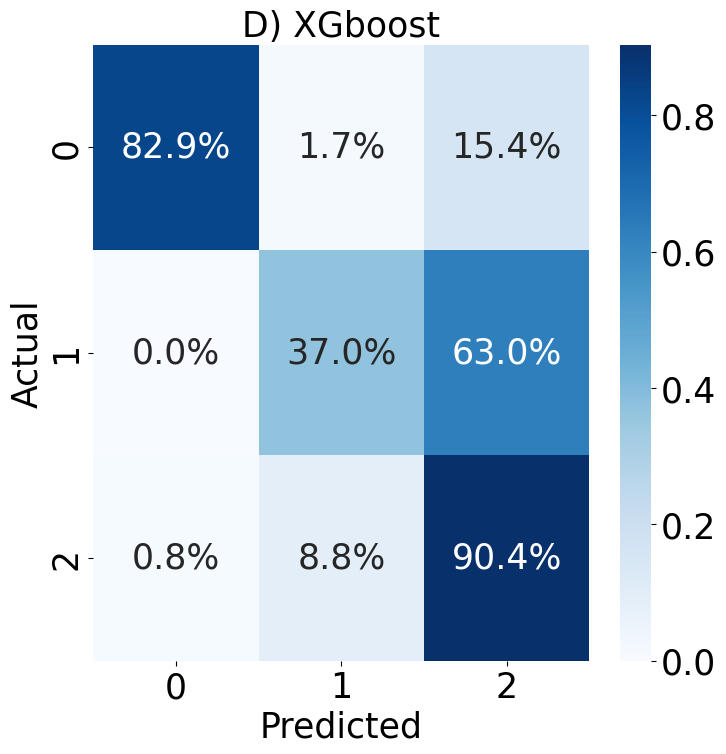

In [72]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('D) XGboost',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# Naive bayes

In [73]:
# Initialize Gaussian Naive Bayes classifier
model5 = GaussianNB()

# Train the classifier
model5.fit(X_train, y_train)

# Predictions
y_pred = model5.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print("Accuracy:", accuracy)
print("Classification Report:\n", report)

Accuracy: 0.43711340206185567
Classification Report:
               precision    recall  f1-score   support

           0       0.44      0.88      0.58       117
           1       0.38      0.65      0.48       119
           2       0.73      0.13      0.22       249

    accuracy                           0.44       485
   macro avg       0.51      0.55      0.43       485
weighted avg       0.57      0.44      0.37       485



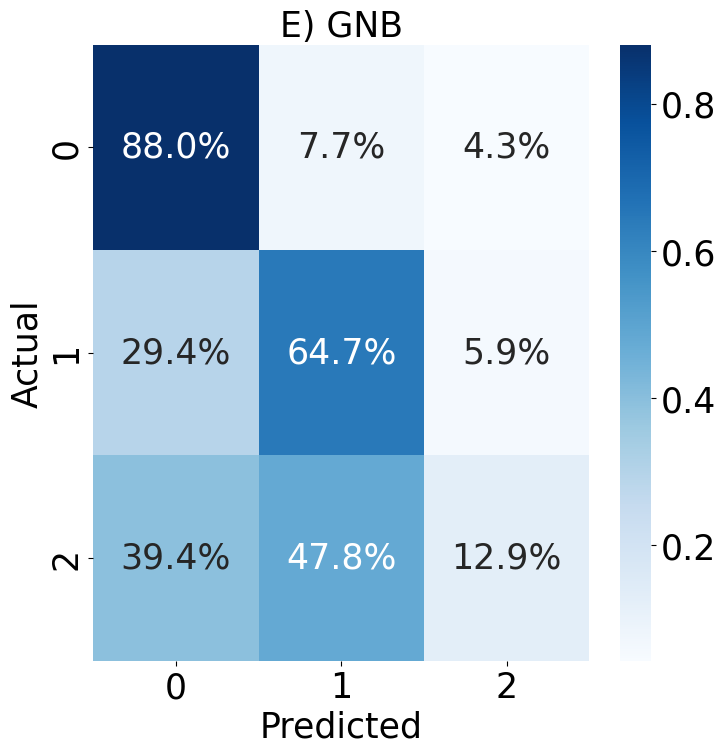

In [74]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('E) GNB',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# Ensemble

In [75]:
from sklearn.ensemble import VotingClassifier

In [76]:
voting_clf = VotingClassifier(
    estimators=[('lr', model1), ('df', model2), ('rf', model3),('xgb', model4),('gnb', model5)],
    voting='hard'  # other options: 'soft' for soft voting
)

# Train the voting classifier
voting_clf.fit(X_train, y_train)

# Make predictions
y_pred = voting_clf.predict(X_test)

/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:457: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:306: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:416: LineSearchWarning: Rounding errors prevent the line search from converging
  warn(msg, LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/utils/optimize.py:203: UserWarning: Line Search failed
  warnings.warn("Line Search failed")


In [77]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print("Accuracy:", accuracy)
print("Classification Report:\n", report)

Accuracy: 0.7463917525773196
Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.83      0.89       117
           1       0.64      0.35      0.45       119
           2       0.70      0.90      0.79       249

    accuracy                           0.75       485
   macro avg       0.76      0.69      0.71       485
weighted avg       0.75      0.75      0.73       485



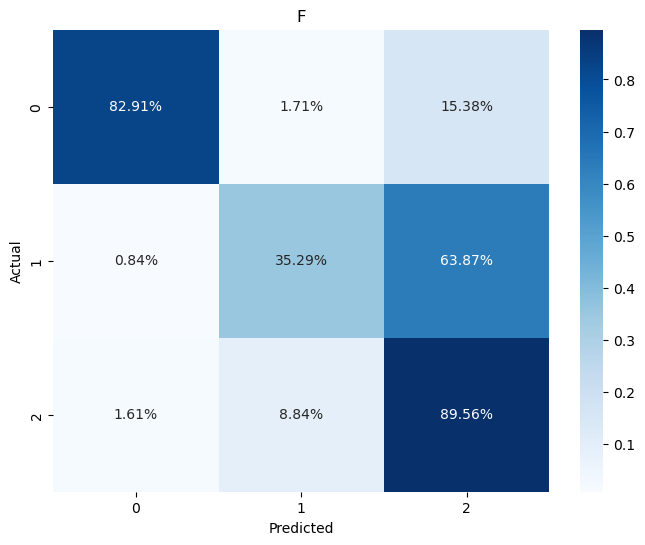

In [78]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_percentage, annot=True, fmt='.2%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('F')
plt.show()

In [89]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

lr_pred = model1.predict(X_test)
df_pred = model2.predict(X_test)
rf_pred = model3.predict(X_test)
xgb_pred = model4.predict(X_test)
gnb_pred = model5.predict(X_test)

X_pred = np.column_stack((lr_pred, df_pred, rf_pred, xgb_pred, gnb_pred))

decision_tree_final = DecisionTreeClassifier(max_depth=5)
decision_tree_final.fit(X_pred, y_test)

final_prediction = decision_tree_final.predict(X_pred)

final_accuracy = accuracy_score(y_test, final_prediction)
print("Accuracy:", final_accuracy)

Accuracy: 0.7608247422680412


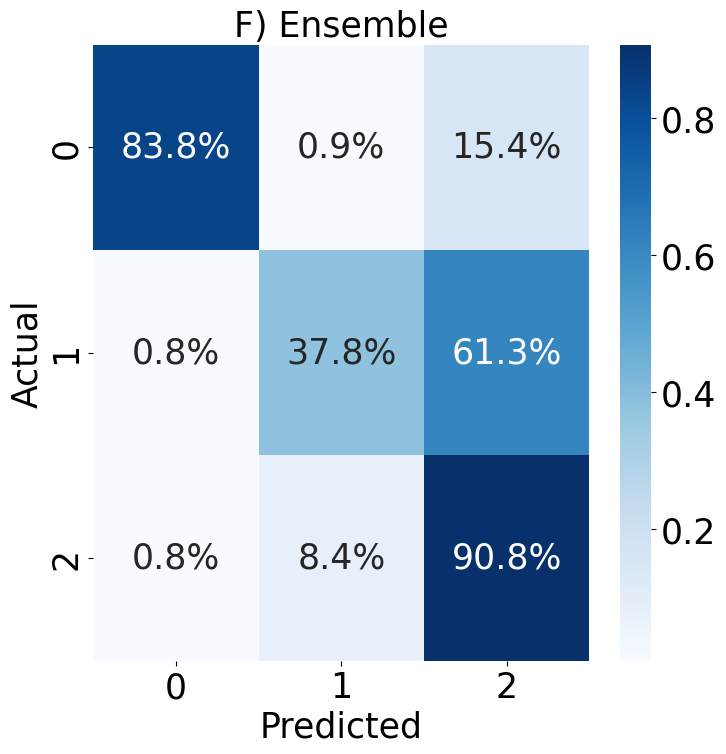

In [91]:
conf_matrix = confusion_matrix(y_test, final_prediction)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('F) Ensemble',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

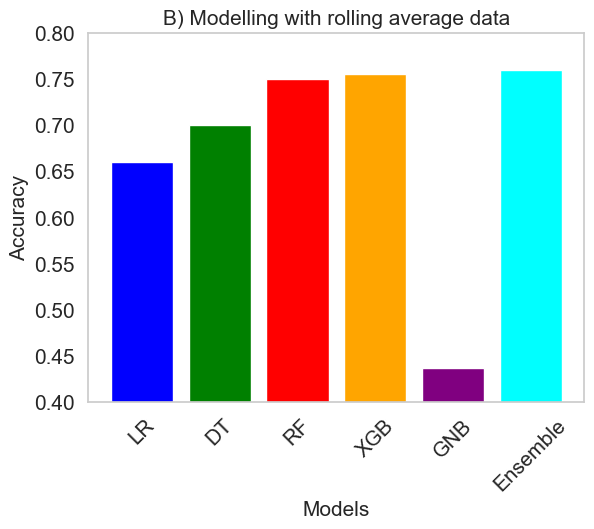

In [150]:
import matplotlib.pyplot as plt

# Sample data
categories = ['LR', 'DT', 'RF', 'XGB','GNB','Ensemble']
values = [0.66, 0.70, 0.75, 0.755,0.437,0.76]
colors = ['blue', 'green', 'red', 'orange', 'purple', 'cyan']
# Create bar plot
plt.bar(categories, values, color=colors)

# Adding title and labels
plt.title('B) Modelling with rolling average data',fontsize=15)
plt.xlabel('Models',fontsize=15)
plt.ylabel('Accuracy',fontsize=15)
plt.xticks(rotation=45, fontsize=15)
plt.yticks(fontsize=15)
plt.ylim(0.4, 0.8)
plt.grid(False)
# Display the plot
plt.show()